# Predictive Maintenance: Machine Failure Prediction

**A reproducible student portfolio study of rare-event classification.**

This notebook explains the complete experiment and reads its measured artifacts. The training code lives in small reusable modules under `src/`. It is not a production deployment or a claim of future-warning performance.

Read the narrative, run the cells in order, and compare each conclusion with the displayed evidence.

*Execution note: all code cells in the delivered notebook were executed sequentially in an in-process IPython session. The build environment blocks kernel sockets, so a separate Jupyter kernel/server could not be launched here. Standard Jupyter use is documented for local execution.*

## 1. Problem definition

Use product type and operational measurements to classify the supplied binary `Machine failure` label. The useful questions are: *How many failures are detected? How many alerts are false? How do these change with the decision threshold?*

The target is failure at an observation. The dataset has no declared future forecast horizon, so this does not demonstrate prediction hours or days before failure.

## 2. Dataset and provenance

We use the **official UCI AI4I 2020 Predictive Maintenance Dataset**, not data generated by this project.

- [Authoritative source](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)
- [Dataset DOI](https://doi.org/10.24432/C5HS5C)
- [CC BY 4.0 dataset license](https://creativecommons.org/licenses/by/4.0/)

The provider describes it as synthetic industrial-style data. A row is an operating observation, not a verified distinct machine. The original CSV and attribution are included; `src.data` can also download it. See `data/README.md` for checksum and manual setup.

Attribution: AI4I 2020 Predictive Maintenance Dataset (2020), UCI Machine Learning Repository. Related paper: Stephan Matzka, *Explainable Artificial Intelligence for Predictive Maintenance Applications* (2020).

## 3. Imports and reproducible settings

Paths work whether the notebook is launched from the repository root or the `notebooks` directory. No machine-specific absolute path is embedded. The default mode displays the measured run. Change only `RUN_TRAINING` to reproduce the full training workflow.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "src/data.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RUN_TRAINING = False
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)

In [2]:
from src.data import (FEATURES, NUMERIC_FEATURES, FAILURE_FLAGS, TARGET,
                      load_dataset, prepare_xy, split_data, audit_dataset, sha256_file)
from src.preprocessing import build_models, build_preprocessor
from src.train import run_experiment
from src.reporting import load_results
from src.predict import predict_sample

REPORTS = ROOT / "reports"
def show_figure(name):
    display(Image(filename=str(REPORTS / "figures" / name)))

## 4. Load and verify the official CSV

The loader verifies the SHA-256 checksum and validates column/target types. A missing file triggers the official download; a changed file raises a clear error instead of being silently accepted.

In [3]:
frame = load_dataset(ROOT / "data/raw/ai4i2020.csv")
print(f"Observed shape: {frame.shape[0]:,} rows × {frame.shape[1]} columns")
print("CSV SHA-256:", sha256_file(ROOT / "data/raw/ai4i2020.csv"))
display(frame.head(3))

Observed shape: 10,000 rows × 14 columns
CSV SHA-256: dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0


## 5. Data quality and class distribution

These full-file checks are limited to schema, missingness, duplicate checks, the target distribution, and a label audit. Sensor–target exploration later uses only the fitting partition.

In [4]:
audit = audit_dataset(frame)
quality = pd.DataFrame({"dtype": frame.dtypes.astype(str),
                        "missing": frame.isna().sum(),
                        "unique_values": frame.nunique()})
display(quality)
print("Complete duplicate rows:", audit["full_duplicate_rows"])
print("Duplicate six-feature combinations:", audit["feature_duplicate_rows"])
display(frame[TARGET].value_counts().rename_axis("label").to_frame("rows"))

Complete duplicate rows: 0
Duplicate six-feature combinations: 0


,dtype,missing,unique_values
UDI,int64,0,10000
Product ID,object,0,10000
Type,object,0,3
Air temperature [K],float64,0,93
Process temperature [K],float64,0,82
Rotational speed [rpm],int64,0,941
Torque [Nm],float64,0,577
Tool wear [min],int64,0,246
Machine failure,int64,0,2
TWF,int64,0,2


,rows
label,
0,9661
1,339


In [5]:
display(Markdown(
    f"There are **{sum(audit['missing_by_column'].values())} missing cells** and "
    f"**{audit['full_duplicate_rows']} full duplicates**. No rows need to be removed for those reasons. "
    f"Failures represent **{audit['failure_rate']:.2%}** of observations. "
    f"An always-no-failure rule would achieve **{1 - audit['failure_rate']:.2%} accuracy** "
    "on the full CSV while detecting no failures. This motivates AP and positive-class metrics."
))

There are **0 missing cells** and **0 full duplicates**. No rows need to be removed for those reasons. Failures represent **3.39%** of observations. An always-no-failure rule would achieve **96.61% accuracy** on the full CSV while detecting no failures. This motivates AP and positive-class metrics.

## 6. Explicit leakage analysis

The five failure-mode columns record outcomes: tool wear failure (TWF), heat dissipation failure (HDF), power failure (PWF), overstrain failure (OSF), and random failure (RNF). They could reveal the answer and are excluded regardless of how strongly each correlates with the target. Identifiers are also excluded; `Type` already supplies the product-quality category.

The target and OR of these flags are not perfectly consistent in the actual CSV. Checking this is a data audit, not a reason to use the flags as predictors or reconstruct the target.

In [6]:
flag_or = frame[FAILURE_FLAGS].max(axis=1)
display(pd.crosstab(flag_or.rename("Any failure flag"), frame[TARGET]))
display(pd.Series(audit["failure_flag_counts"], name="Observed flag count"))
print("Mismatching rows:", audit["flag_or_target_mismatches"])
print("Target=1 but no flag:", audit["target_1_without_flag"])
print("Target=0 but at least one flag:", audit["target_0_with_flag"])

Mismatching rows: 27
Target=1 but no flag: 9
Target=0 but at least one flag: 18


Machine failure,0,1
Any failure flag,,
0,9643,9
1,18,330


TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
Name: Observed flag count, dtype: int64

**Decision:** preserve every original row and the original `Machine failure` label. Exclude all five flags and both identifiers. The official narrative contains counts that differ from the CSV; this experiment's counts come from the CSV. The inconsistency does not make outcome flags legitimate sensor inputs.

## 7. Features, target, and early split

We split **before exploratory feature/target analysis**, a small ordering change that protects the held-out data. First hold out 20% for final testing with stratification; reserve 20% of the remaining 80% for threshold validation. This produces 64% fitting / 16% validation / 20% test.

A random split is appropriate for this declared benchmark exercise, but cannot establish forward-time performance. UCI's generated sensor sequences have local dependence. A real project needs time/group-aware evaluation.

In [7]:
X, y = prepare_xy(frame)
partitions = split_data(frame)
fit_index = partitions["fit"]
fit_frame = frame.loc[fit_index]
X_fit, y_fit = X.loc[fit_index], y.loc[fit_index]
assert set(X.columns) == set(FEATURES)
assert not set(FAILURE_FLAGS + [TARGET, "UDI", "Product ID"]) & set(X.columns)
display(pd.DataFrame({name: {"rows": len(index), "failures": int(y.loc[index].sum()),
                             "failure_rate": float(y.loc[index].mean())}
                      for name, index in partitions.items()}).T)

,rows,failures,failure_rate
fit,6400.0,217.0,0.0339
validation,1600.0,54.0,0.0338
test,2000.0,68.0,0.0340


### Load a measured run or explicitly reproduce it

`RUN_TRAINING=True` runs comparison, tuning, validation threshold selection, and a single final test evaluation through `src.train`. With the default `False`, the notebook reads the existing reports and does **not** reevaluate the test set. Missing reports require running training first. Source/dataset hashes guard against displaying stale results after code or data changes.

This preserves one source of truth between command-line training, the README, and the notebook. If you change modeling decisions after seeing test results, you need a new independent test set to claim unbiased evaluation.

In [8]:
if RUN_TRAINING:
    run_experiment(ROOT / "data/raw/ai4i2020.csv", ROOT)
if not (REPORTS / "results.json").exists():
    raise FileNotFoundError("Run python -m src.train, or set RUN_TRAINING=True.")
results = load_results(ROOT)
assert results["dataset_sha256"] == sha256_file(ROOT / "data/raw/ai4i2020.csv")
changed = [name for name, digest in results["source_sha256"].items()
           if sha256_file(ROOT / "src" / name) != digest]
if changed:
    raise RuntimeError(f"Code changed since recorded run: {changed}. Reproduce training.")
print("Recorded run:", results["completed_at_utc"])
print("Python:", results["python_version"])
display(pd.Series(results["package_versions"], name="Observed version"))

Recorded run: 2026-10-05T09:26:10.112041+00:00
Python: 3.12.14


numpy             2.3.5
pandas            2.2.3
matplotlib       3.10.8
scikit-learn      1.8.0
scipy            1.17.0
joblib            1.5.3
threadpoolctl     3.6.0
Name: Observed version, dtype: object

## 8. Training-only exploratory analysis

Inspect distributions, class imbalance, target relationships, and meaningful numeric correlations. The plots were created by `src.eda.create_eda()` on fitting rows only. No test plots are used for model choices.

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,6400,6400.0000,6400.0000,6400.0000,6400.0000,6400.0000
unique,3,NaN,NaN,NaN,NaN,NaN
top,L,NaN,NaN,NaN,NaN,NaN
freq,3856,NaN,NaN,NaN,NaN,NaN
mean,NaN,300.0003,310.0036,1539.3612,40.0107,107.9645
std,NaN,1.9948,1.4805,180.8641,9.9982,63.5972
min,NaN,295.3000,305.7000,1168.0000,3.8000,0.0000
25%,NaN,298.3000,308.8000,1423.0000,33.3000,53.0000
50%,NaN,300.1000,310.1000,1503.0000,40.1000,107.0000
75%,NaN,301.5000,311.0000,1614.0000,46.8000,163.0000


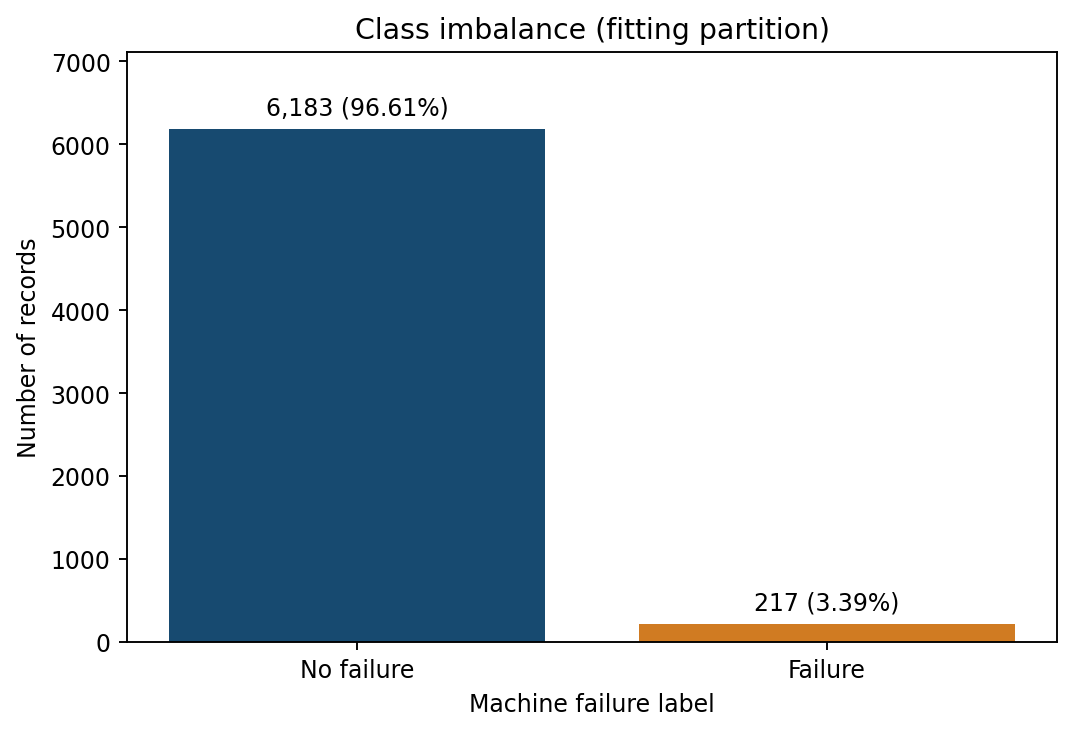

In [9]:
display(fit_frame[FEATURES].describe(include="all"))
show_figure("target_distribution.png")

**Interpretation:** a low failure fraction makes overall accuracy an incomplete objective. The dummy reference in the comparison below shows what can be achieved without learning sensor patterns. The medians and ranges also confirm that the numerical features use very different scales.

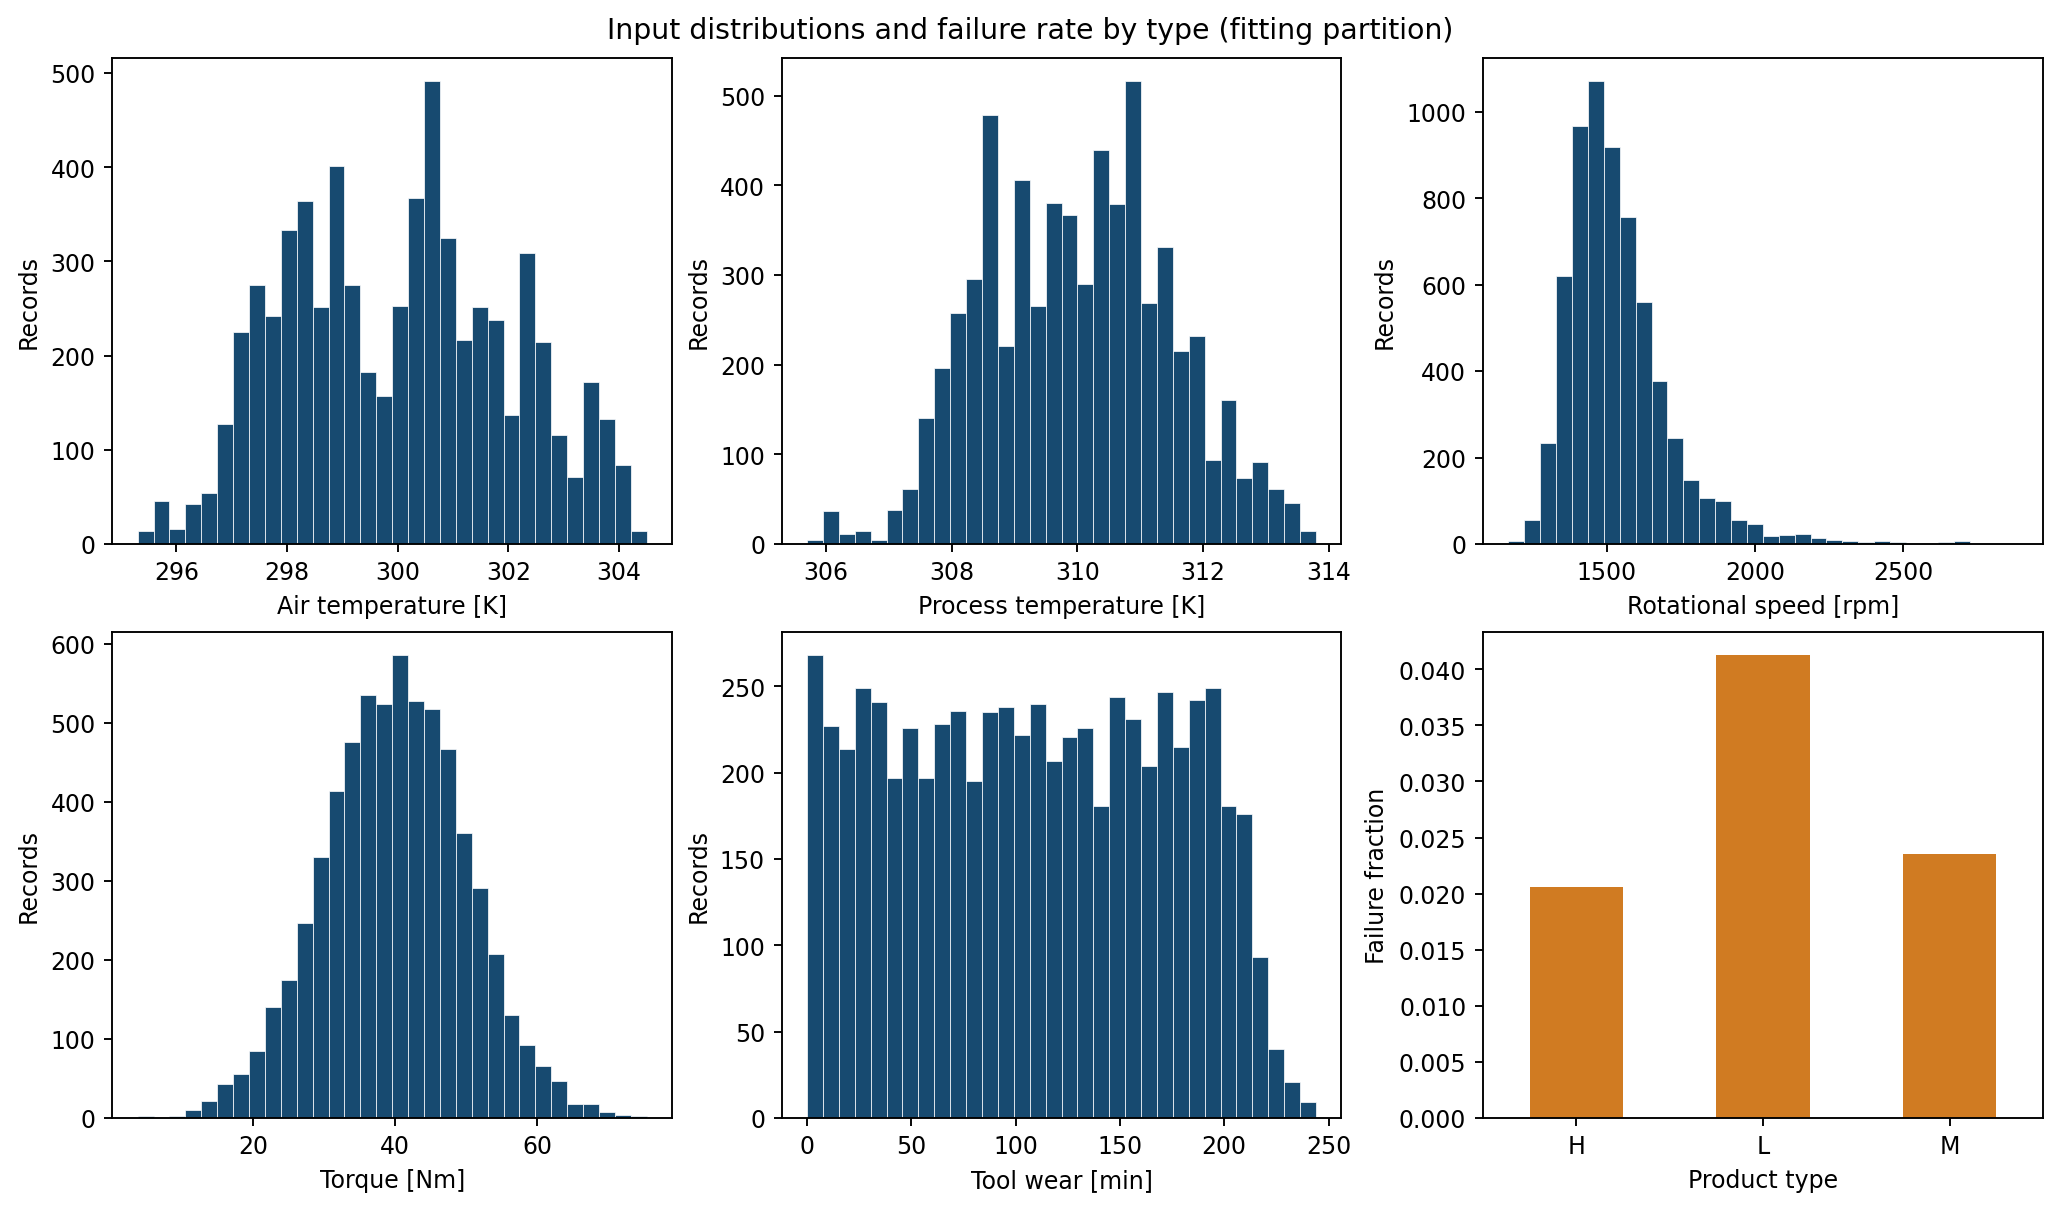

,Type,rows,failures,failure_rate
0,H,630,13,0.0206
1,L,3856,159,0.0412
2,M,1914,45,0.0235


In [10]:
show_figure("feature_distributions.png")
display(pd.read_csv(REPORTS / "fit_failure_rate_by_type.csv"))

**Interpretation:** product-type frequencies and failure rates differ, so we retain the product category. Rates for a smaller group are less stable. A feature histogram describes support and shape; it does not by itself establish predictive value. Scaling is applied only where the model benefits from it.

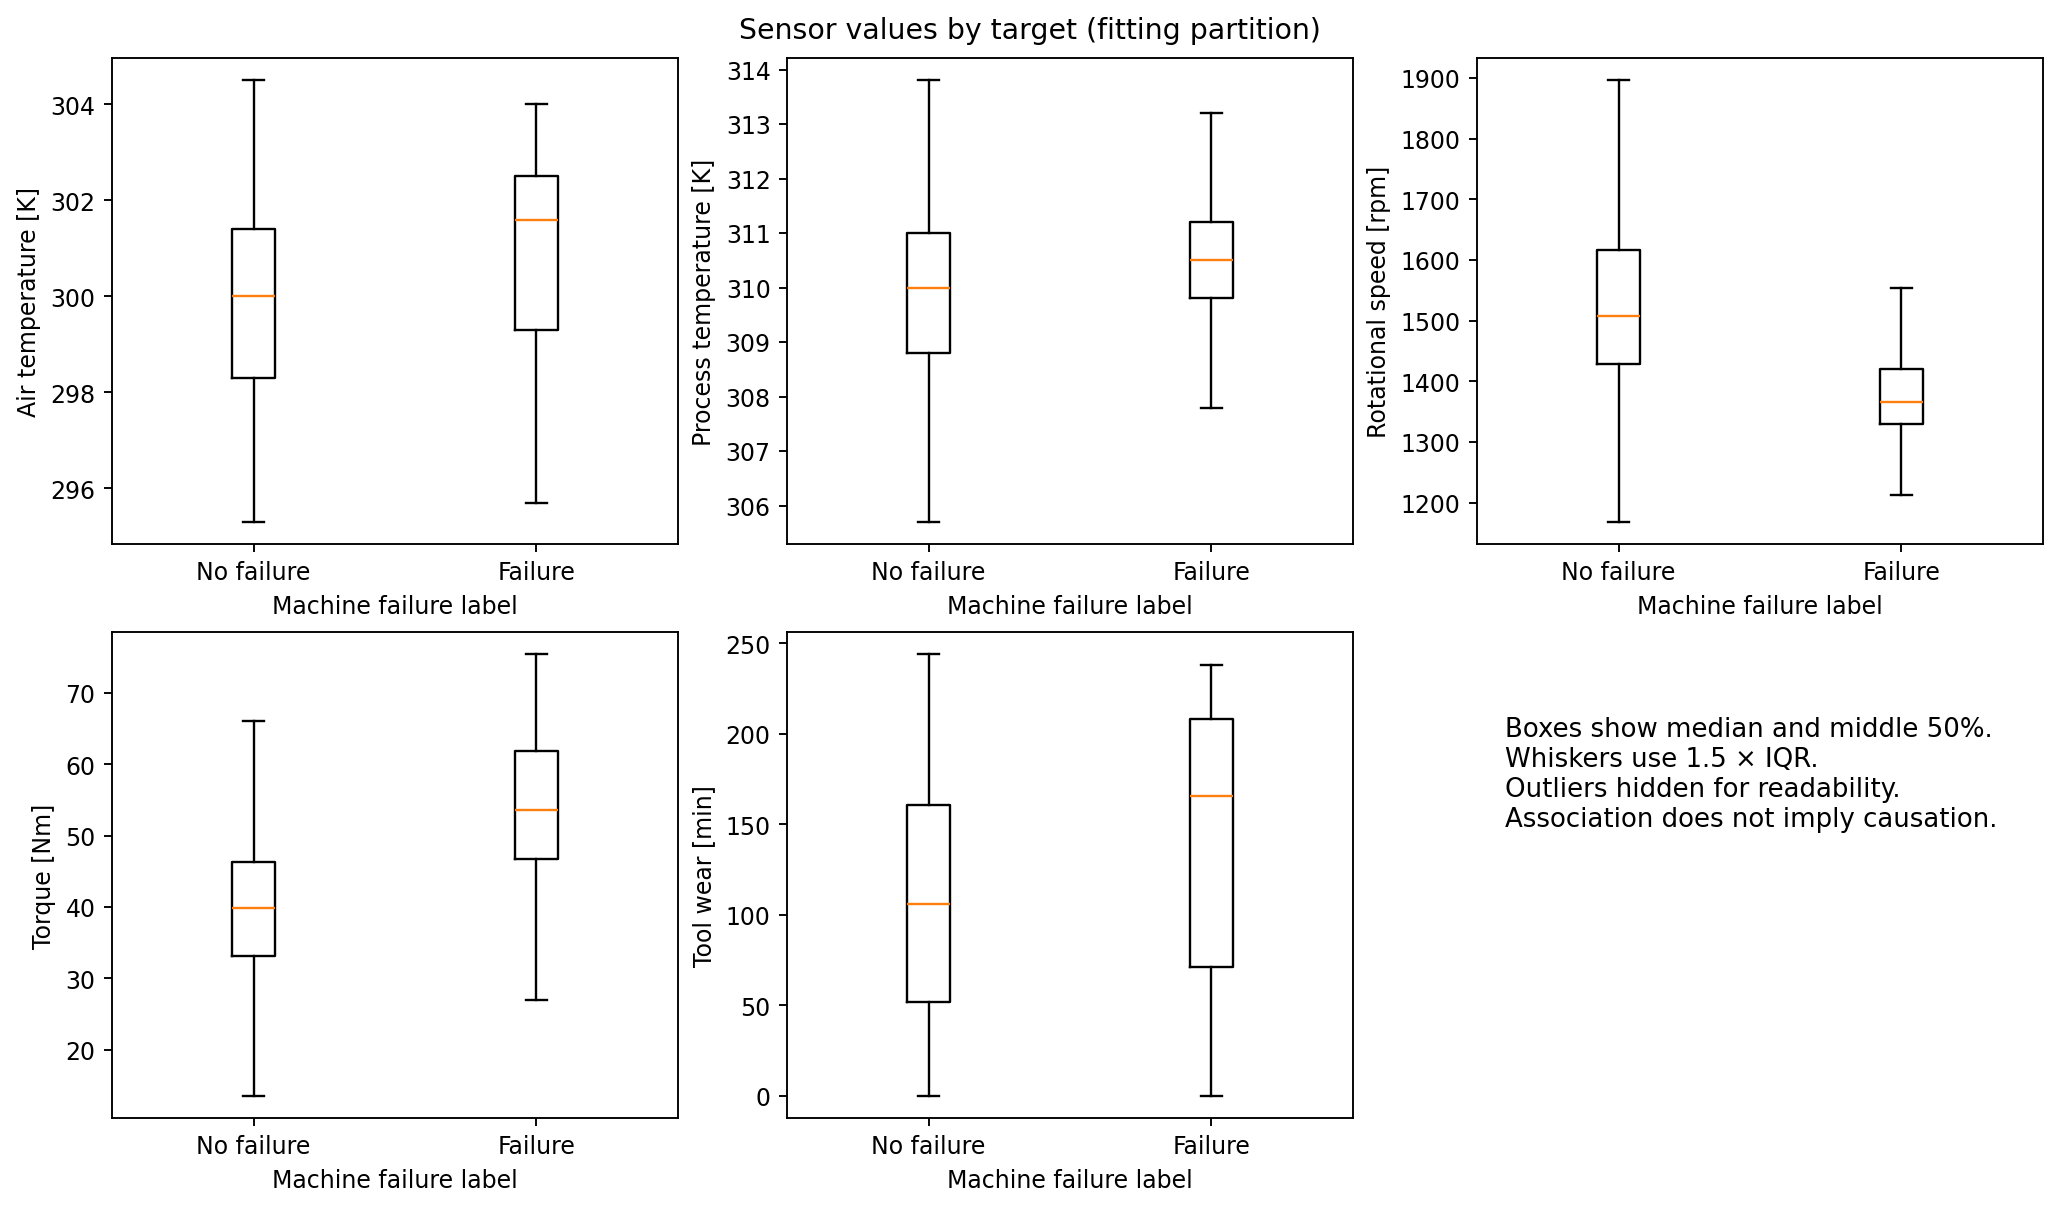

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Machine failure,,,,,
0,299.9651,309.9911,1540.9694,39.6364,106.7893
1,301.0037,310.3594,1493.5392,50.6756,141.4516


Mean torque is **50.68 Nm** for failure rows versus **39.64 Nm** for non-failures. Mean wear is **141.45** versus **106.79 minutes**. These are associations in this synthetic benchmark, not causal estimates. Overlapping distributions mean a single simple cutoff is unlikely to explain all failures.

In [11]:
show_figure("features_by_target.png")
means = fit_frame.groupby(TARGET)[NUMERIC_FEATURES].mean()
display(means)
display(Markdown(
    f"Mean torque is **{means.loc[1, 'Torque [Nm]']:.2f} Nm** for failure rows versus "
    f"**{means.loc[0, 'Torque [Nm]']:.2f} Nm** for non-failures. Mean wear is "
    f"**{means.loc[1, 'Tool wear [min]']:.2f}** versus **{means.loc[0, 'Tool wear [min]']:.2f} minutes**. "
    "These are associations in this synthetic benchmark, not causal estimates. "
    "Overlapping distributions mean a single simple cutoff is unlikely to explain all failures."
))

Air/process temperature r: 0.8766
Speed/torque r: -0.8737


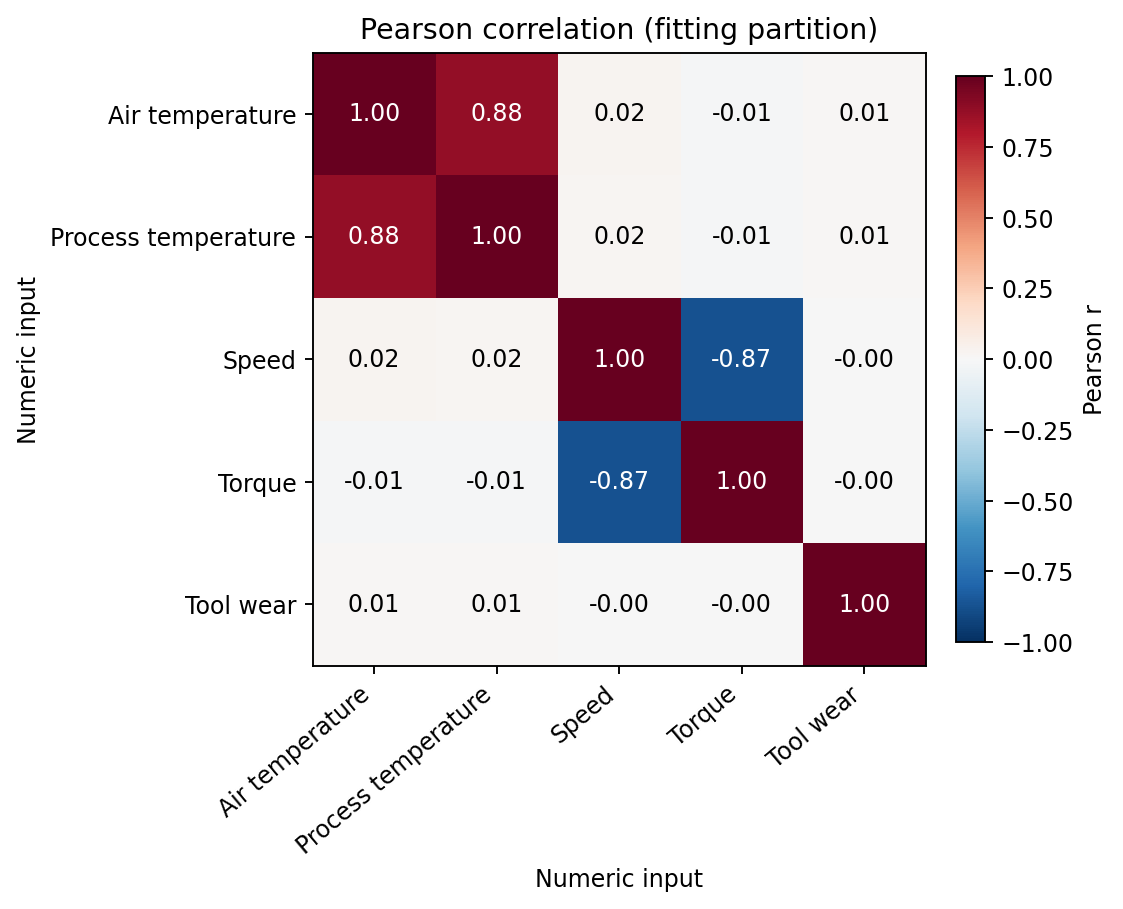

In [12]:
show_figure("correlation_matrix.png")
correlations = fit_frame[NUMERIC_FEATURES].corr()
print("Air/process temperature r:", round(correlations.loc["Air temperature [K]", "Process temperature [K]"], 4))
print("Speed/torque r:", round(correlations.loc["Rotational speed [rpm]", "Torque [Nm]"], 4))

**Interpretation:** strong correlations show shared information between temperatures and an inverse speed/torque relationship. Correlation measures linear association only. It neither proves causality nor captures every useful nonlinear relationship. Correlation also complicates later permutation-importance interpretation.

## 9. Fold-local preprocessing

All models use `Pipeline` and `ColumnTransformer`. Numeric values use median imputation; category values use most-frequent imputation and dense one-hot encoding. Logistic regression also uses `StandardScaler`; tree models do not need scaling. No preprocessing is fit on all rows before splitting.

The original CSV has no missing data, but the imputer defines sensible training-fold behavior. The public prediction command still rejects incomplete samples. Dense encoding is small and compatible with histogram boosting.

In [13]:
preprocessor = build_preprocessor(scale_numeric=True)
transformed_fit = preprocessor.fit_transform(X_fit)
print("Fitting matrix shape:", transformed_fit.shape)
print("Transformed columns:", list(preprocessor.get_feature_names_out()))
assert transformed_fit.shape == (len(X_fit), 8)
assert np.isfinite(transformed_fit).all()
print("Candidate pipelines:", list(build_models()))

Fitting matrix shape: (6400, 8)
Transformed columns: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H', 'Type_L', 'Type_M']
Candidate pipelines: ['Dummy', 'Logistic Regression', 'Random Forest', 'HistGradientBoosting']


This preprocessing fit is a teaching demonstration using fitting rows only. The actual experiment clones and fits each model's complete pipeline separately within each CV fold. It never reuses this demonstration matrix for CV.

## 10. Baseline and model choices

- **DummyClassifier (`prior`)** estimates prevalence and predicts the majority class: a necessary no-skill reference.
- **Logistic Regression** is the interpretable linear reference, with balanced weights and scaled numeric features.
- **Random Forest** tests nonlinear interactions using an ensemble of independently randomized trees.
- **HistGradientBoostingClassifier** tests a sequential boosted-tree approach with no additional ML library.

The three real comparison models begin with balanced class weights. Tuning subsequently compares balanced versus unweighted settings for the selected family. No SMOTE is used.

In [14]:
comparison = pd.read_csv(REPORTS / "model_comparison.csv")
columns = ["model", "average_precision_mean", "roc_auc_mean", "precision_mean",
           "recall_mean", "f1_mean", "accuracy_mean"]
display(comparison.loc[comparison.model == "Dummy", columns])

,model,average_precision_mean,roc_auc_mean,precision_mean,recall_mean,f1_mean,accuracy_mean
3,Dummy,0.0339,0.5,0.0,0.0,0.0,0.9661


**Interpretation:** the dummy's accuracy reflects the majority class. Its failure recall and F1 expose its lack of usefulness for finding failures. Its AP gives a prevalence-based reference.

## 11. Model comparison and stratified cross-validation

The fixed setup uses `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` on fitting rows only. Every candidate receives the same folds. `src.train.compare_models()` saves all fold scores and their summaries.

Mean **Average Precision** selects the model family because failure retrieval matters more than majority-class accuracy. Precision, recall, and F1 in this comparison use each candidate's default classification rule, before the later threshold-selection step.

In [15]:
display(comparison[columns + ["average_precision_std"]])
fold_scores = pd.read_csv(REPORTS / "cv_fold_scores.csv")
display(fold_scores.pivot(index="fold", columns="model", values="average_precision"))
display(Markdown(f"The declared rule selected **{results['selected_model']}**. "
                 "Close CV scores are not proof that one family is universally superior. "
                 "Fold variability is descriptive, not a confidence interval."))

,model,average_precision_mean,roc_auc_mean,precision_mean,recall_mean,f1_mean,accuracy_mean,average_precision_std
0,HistGradientBoosting,0.7373,0.9642,0.6393,0.7647,0.6943,0.9770,0.0752
1,Random Forest,0.7268,0.9615,0.8551,0.3865,0.5309,0.9770,0.0968
2,Logistic Regression,0.4594,0.9040,0.1438,0.8016,0.2437,0.8314,0.0361
3,Dummy,0.0339,0.5000,0.0000,0.0000,0.0000,0.9661,0.0004


model,Dummy,HistGradientBoosting,Logistic Regression,Random Forest
fold,,,,
1,0.0336,0.7962,0.4919,0.8070
2,0.0336,0.7407,0.4666,0.6571
3,0.0336,0.6275,0.3976,0.5914
4,0.0344,0.8155,0.4660,0.7958
5,0.0344,0.7066,0.4750,0.7825


The declared rule selected **HistGradientBoosting**. Close CV scores are not proof that one family is universally superior. Fold variability is descriptive, not a confidence interval.

## 12. Modest hyperparameter tuning

Only the best real model family is tuned. `GridSearchCV` tests eight configurations with the same five folds and AP scoring. The search includes the original comparison configuration. The strongest setting is fit on all fitting rows.

Selecting a family and parameters on reused CV folds creates optimistic selection scores. The independent test partition is reserved for the final assessment; nested CV is a possible future improvement.

In [16]:
print("Grid:")
print(json.dumps(results["tuning_grid"], indent=2))
print("Best parameters:", results["best_parameters"])
print(f"Best tuning CV AP: {results['best_cv_average_precision']:.4f}")
tuning = pd.read_csv(REPORTS / "tuning_results.csv")
display(tuning[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
        .sort_values("rank_test_score"))

Grid:
{
  "classifier__max_leaf_nodes": [
    15,
    31
  ],
  "classifier__l2_regularization": [
    0.0,
    1.0
  ],
  "classifier__class_weight": [
    null,
    "balanced"
  ]
}
Best parameters: {'classifier__class_weight': None, 'classifier__l2_regularization': 0.0, 'classifier__max_leaf_nodes': 31}
Best tuning CV AP: 0.7752


,params,mean_test_score,std_test_score,rank_test_score
1,"{'classifier__class_weight': None, 'classifier...",0.7752,0.0474,1
0,"{'classifier__class_weight': None, 'classifier...",0.7735,0.0492,2
3,"{'classifier__class_weight': None, 'classifier...",0.7725,0.0553,3
7,"{'classifier__class_weight': 'balanced', 'clas...",0.7645,0.0574,4
6,"{'classifier__class_weight': 'balanced', 'clas...",0.7617,0.0568,5
2,"{'classifier__class_weight': None, 'classifier...",0.7602,0.0572,6
5,"{'classifier__class_weight': 'balanced', 'clas...",0.7554,0.0635,7
4,"{'classifier__class_weight': 'balanced', 'clas...",0.7373,0.0672,8


**Interpretation:** the selected parameters are the best within a small declared grid, not a claim of a globally optimal model. Class weighting is selected empirically. Model complexity stays small enough to study and reproduce on a normal laptop.

## 13. Validation-only threshold selection

Before touching final test predictions, evaluate thresholds from 0.05 to 0.95 in increments of 0.05 on the validation partition. Choose maximum F1; choose the higher threshold if tied. This is an explicit educational rule, not an economic optimum.

Keep the same model fit on the fitting partition afterward. Refitting on validation rows could change score distributions and invalidate the operating threshold. The selected model's output is an **uncalibrated probability score**.

Frozen threshold: 0.1


,threshold,precision,recall,f1,tn,fp,fn,tp
0,0.05,0.6230,0.7037,0.6609,1523,23,16,38
1,0.10,0.6981,0.6852,0.6916,1530,16,17,37
4,0.25,0.7500,0.6111,0.6735,1535,11,21,33
9,0.50,0.8611,0.5741,0.6889,1541,5,23,31
14,0.75,0.8667,0.4815,0.6190,1542,4,28,26


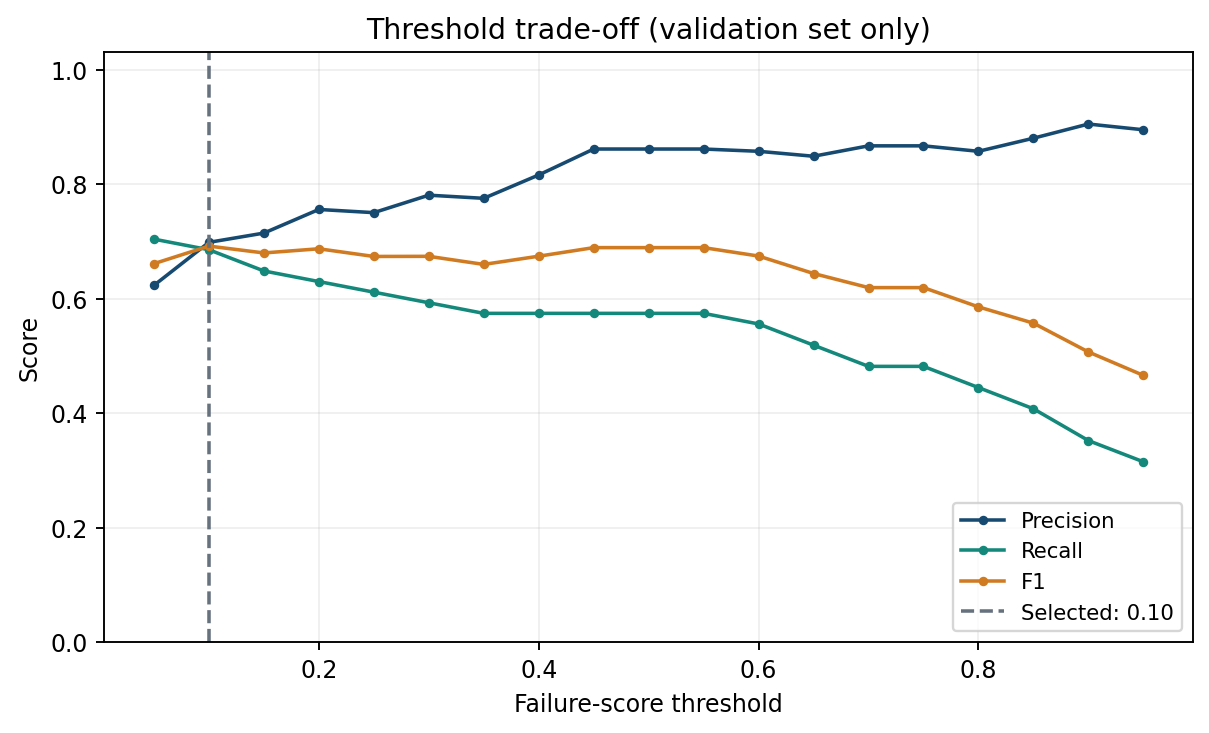

threshold       0.1000
precision       0.6981
recall          0.6852
f1              0.6916
tn           1530.0000
fp             16.0000
fn             17.0000
tp             37.0000
Name: Selected validation point, dtype: float64

In [17]:
thresholds = pd.read_csv(REPORTS / "threshold_analysis.csv")
display(thresholds.loc[thresholds.threshold.isin([0.05, 0.10, 0.25, 0.50, 0.75])])
show_figure("threshold_analysis.png")
print("Frozen threshold:", results["threshold"])
display(pd.Series(results["validation_at_selected_threshold"], name="Selected validation point"))

**Interpretation:** lowering a threshold cannot reduce the number of predicted positives and usually trades more detected failures for more false alarms. Precision need not change monotonically in a finite sample. The selected validation score is itself optimized, so it is not an unbiased estimate. We do not search thresholds on test data.

## 14. Single final held-out test evaluation

The pipeline and threshold were frozen before one call produced the test score vector. All metrics, the confusion matrix, and curves below come from that vector, saved as `reports/test_predictions.csv`. Reading it again is reporting, not another model-selection experiment.

AP is scikit-learn's non-interpolated Average Precision, **not** trapezoidal PR-AUC. Accuracy, precision, recall, and F1 use the selected threshold; ROC-AUC and AP use scores across thresholds.

accuracy             0.9835
precision            0.7465
recall               0.7794
f1                   0.7626
roc_auc              0.9664
average_precision    0.8430
Name: Final test, dtype: float64

,precision,recall,f1-score,support
No failure,0.9922,0.9907,0.9915,1932.0
Failure,0.7465,0.7794,0.7626,68.0
macro avg,0.8694,0.8850,0.8770,2000.0
weighted avg,0.9839,0.9835,0.9837,2000.0


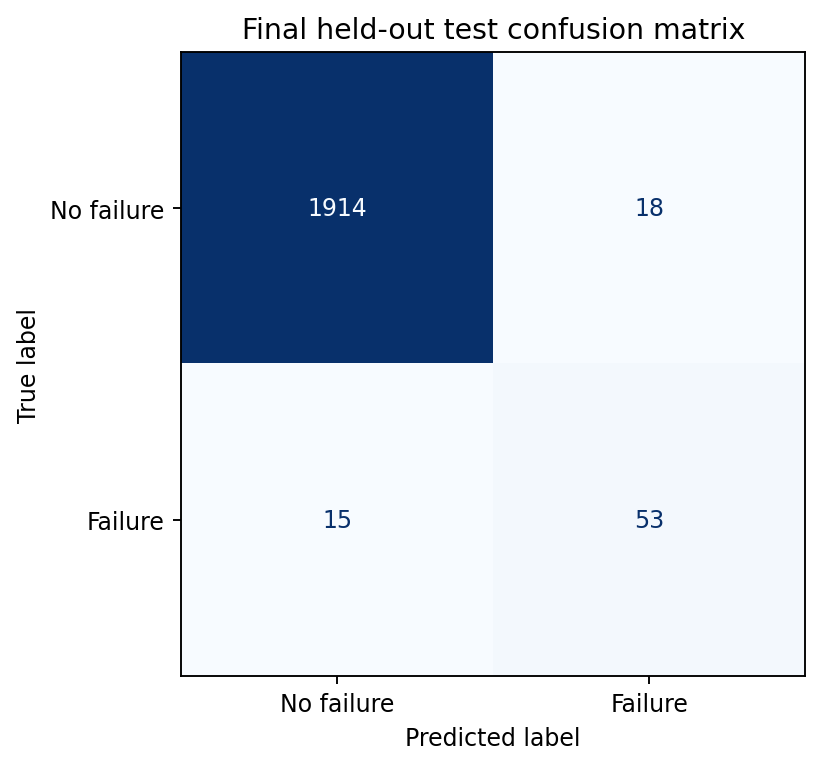

In [18]:
metrics = results["test_metrics"]
metric_names = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]
display(pd.Series({name: metrics[name] for name in metric_names}, name="Final test"))
display(pd.read_csv(REPORTS / "classification_report.csv", index_col=0))
show_figure("confusion_matrix.png")

At threshold **0.10**, the model detected **53 of 68** test failures, missed **15**, and raised **18** false alarms. **1914** non-failure observations were correctly cleared. These counts describe the benchmark split; they are not projected factory outcomes.

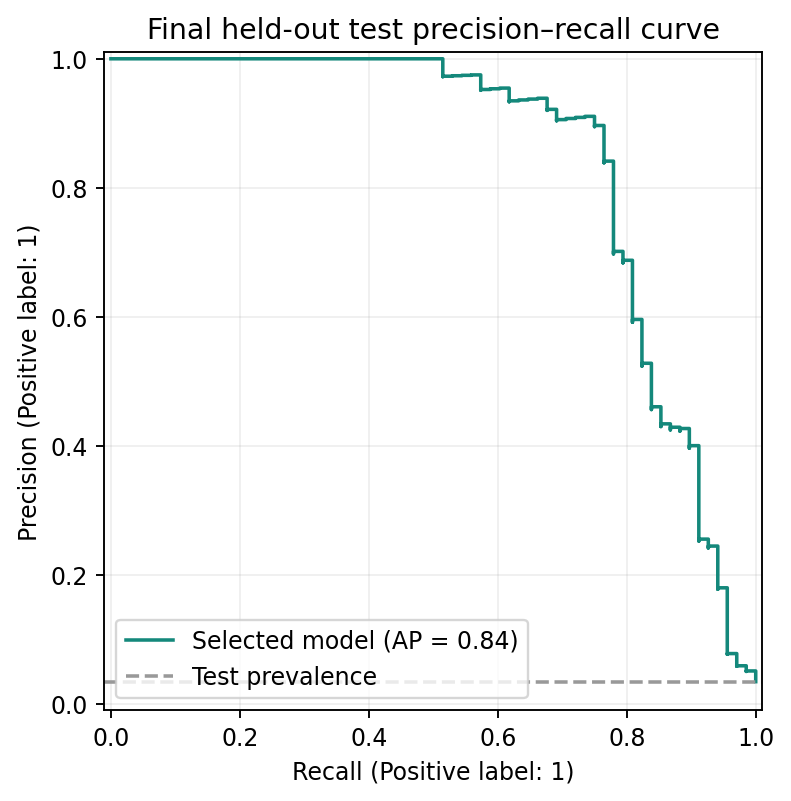

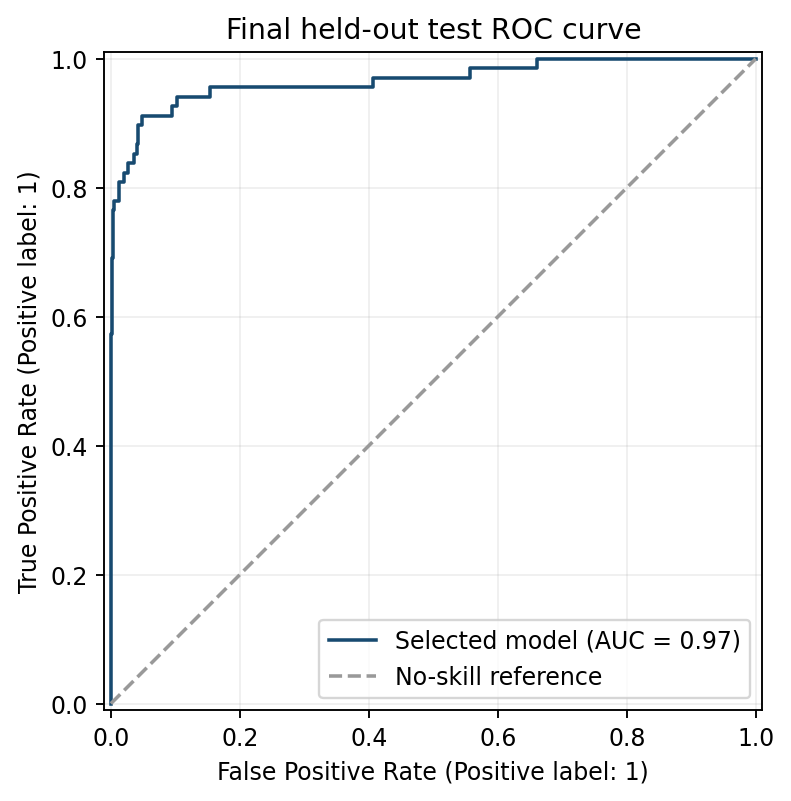

In [19]:
tn, fp = metrics["confusion_matrix"][0]
fn, tp = metrics["confusion_matrix"][1]
display(Markdown(
    f"At threshold **{results['threshold']:.2f}**, the model detected **{tp} of {tp + fn}** "
    f"test failures, missed **{fn}**, and raised **{fp}** false alarms. "
    f"**{tn}** non-failure observations were correctly cleared. "
    "These counts describe the benchmark split; they are not projected factory outcomes."
))
show_figure("precision_recall_curve.png")
show_figure("roc_curve.png")

**Interpretation:** test metrics describe generalization to this random holdout. Positive-class counts matter: a modest change in detected failures changes recall noticeably. The test PR curve's prevalence line is a no-skill reference. Plotting the curve does not authorize choosing a new test-optimized threshold.

## 15. Model interpretation

Permutation importance uses validation rows, AP scoring, ten repeats, and the fixed model. Each original input is shuffled as a whole, including `Type` before encoding. It is model-agnostic and does not require SHAP.

We calculated this before final test evaluation and did not use it to alter the feature set.

,feature,importance_mean,importance_std
0,Torque [Nm],0.4929,0.0223
1,Air temperature [K],0.4623,0.0235
2,Rotational speed [rpm],0.3239,0.0365
3,Process temperature [K],0.2963,0.0349
4,Tool wear [min],0.2913,0.0334
5,Type,0.0594,0.0211


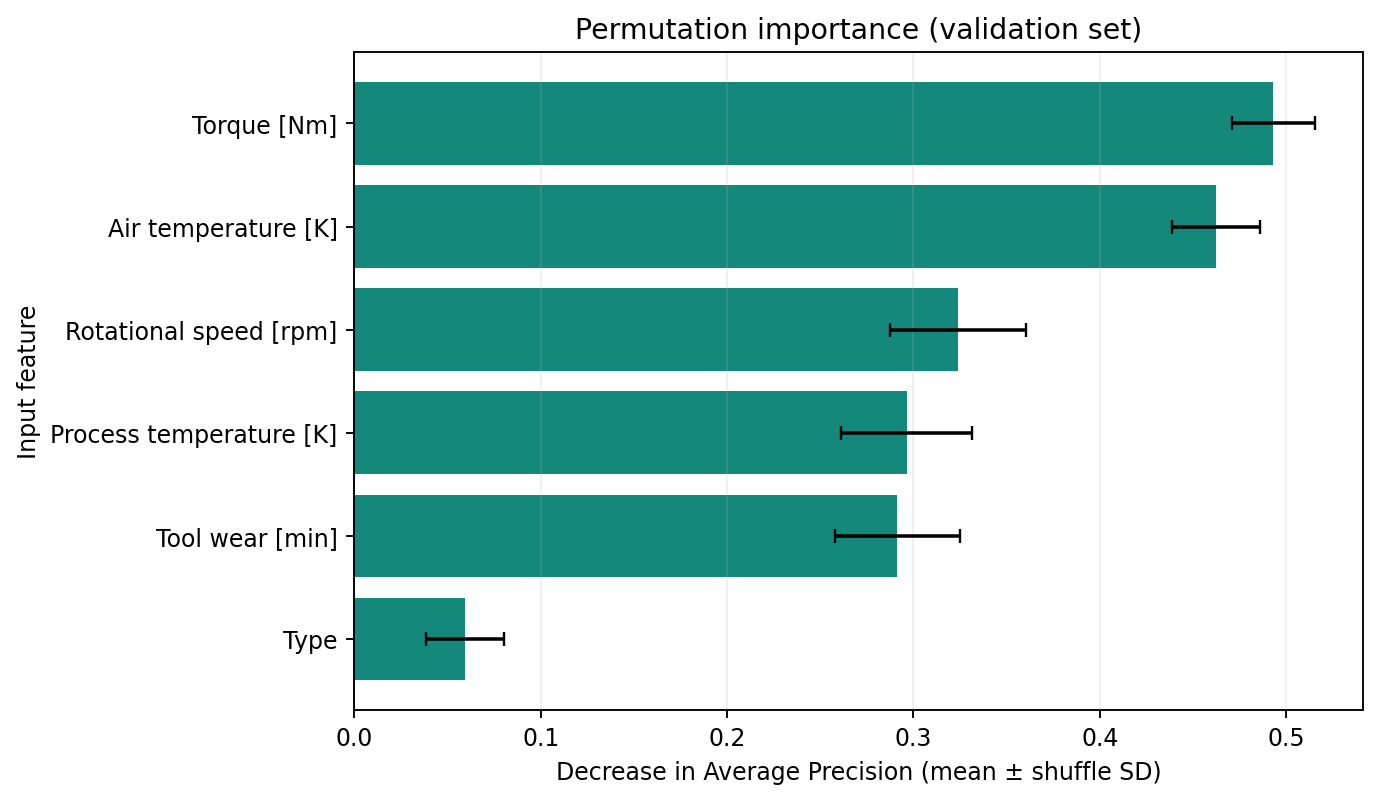

The largest measured AP decreases are for **Torque [Nm], Air temperature [K], Rotational speed [rpm]**. The error bars represent shuffle standard deviation. Correlated features can substitute for one another, and permutation can create unrealistic combinations. Importance does not establish causality.

In [20]:
importance = pd.read_csv(REPORTS / "feature_importance.csv")
display(importance)
show_figure("feature_importance.png")
top_features = ", ".join(importance.feature.head(3))
display(Markdown(f"The largest measured AP decreases are for **{top_features}**. "
                 "The error bars represent shuffle standard deviation. "
                 "Correlated features can substitute for one another, and permutation can create "
                 "unrealistic combinations. Importance does not establish causality."))

## 16. Saved model and one-sample inference

The artifact contains the entire preprocessing/model pipeline, the frozen threshold, input names, training ranges, dataset hash, and scikit-learn version. Only load trusted joblib artifacts. A new environment should retrain or use matching numerical-library versions.

The example is copied from real UCI row 1. It demonstrates the interface, not independent model evaluation.

In [21]:
sample = json.loads((ROOT / "examples/machine_sample.json").read_text())
display(pd.Series(sample, name="Example inputs (UDI=1)"))
model_path = ROOT / "models/failure_model.joblib"
if model_path.exists():
    assert sha256_file(model_path) == results["model_sha256"]
    display(pd.Series(predict_sample(sample, model_path), name="Prediction"))
else:
    print("A Git clone omits models. Run python -m src.train to create the model artifact.")

Type                           M
Air temperature [K]        298.1
Process temperature [K]    308.6
Rotational speed [rpm]      1551
Torque [Nm]                 42.8
Tool wear [min]                0
Name: Example inputs (UDI=1), dtype: object

predicted_class                           0
failure_probability                     0.0
threshold                               0.1
model                  HistGradientBoosting
Name: Prediction, dtype: object

## 17. Software checks and reproducibility

From the repository root, run:

```bash
python -m src.data
python -m src.train
python -m pytest -q
python -m src.predict --sample-file examples/machine_sample.json
```

Tests check official data provenance, exclusion of outcome columns, disjoint stratified partitions, fold-local imputation, finite encoded outputs, invalid input rejection, serialization and stored-threshold behavior, and agreement between saved metrics and saved predictions. Test-fixture mutations are never used for the model's reported results.

`results.json` records versions, seeds, file hashes, split counts, selected parameters, and metrics. Repeating the experiment with the same environment should reproduce the numerical result, but timestamps and timings naturally differ. `requirements-repro.txt` records the numerical versions used for the delivered run.

## 18. Conclusions from the actual run

In [22]:
conclusions = [
    f"1. The selected model was **{results['selected_model']}**, with tuning CV AP **{results['best_cv_average_precision']:.4f}**.",
    f"2. At the validation-selected threshold **{results['threshold']:.2f}**, final test precision was **{metrics['precision']:.4f}**, recall **{metrics['recall']:.4f}**, F1 **{metrics['f1']:.4f}**, and AP **{metrics['average_precision']:.4f}**.",
    f"3. The concrete trade-off was **{fn} missed failures** and **{fp} false alarms**.",
    "4. Outcome-column exclusion, fold-local preprocessing, and separate threshold validation are as important to the credibility of this result as classifier choice.",
]
display(Markdown(chr(10).join(conclusions)))

1. The selected model was **HistGradientBoosting**, with tuning CV AP **0.7752**.
2. At the validation-selected threshold **0.10**, final test precision was **0.7465**, recall **0.7794**, F1 **0.7626**, and AP **0.8430**.
3. The concrete trade-off was **15 missed failures** and **18 false alarms**.
4. Outcome-column exclusion, fold-local preprocessing, and separate threshold validation are as important to the credibility of this result as classifier choice.

## 19. Limitations

- Synthetic benchmark data cannot establish live-factory performance or savings.
- The label is same-observation failure, not a defined future prediction horizon.
- Random-walk sensor generation means neighboring rows may be dependent; a random split can overstate performance relative to future-period or new-machine evaluation.
- The target/flag discrepancies remain unresolved; the supplied target is preserved.
- Rare failures make validation and test metrics sensitive to the sampled cases. CV fold SD and permutation shuffle SD are not deployment confidence intervals.
- Model/parameter selection reuses CV folds; the winning CV value is a selection score.
- F1-based thresholding assumes no actual financial cost model. Scores were not calibrated.
- No industrial deployment, stream processing, drift monitoring, or professional work experience is claimed.

## 20. Realistic next steps

1. Define the required advance-warning horizon and collect timestamped, machine-grouped operational data.
2. Evaluate on future periods and unseen machines, including operating-condition changes.
3. Resolve label semantics with the provider and track genuine maintenance outcomes.
4. Estimate false-alarm/missed-failure costs and study calibration using additional validation data.
5. Use repeated or nested CV for stronger comparisons between close model families.

For interview preparation, continue with `INTERVIEW_GUIDE.md`. Understand each implemented decision before using the resume material.